In [65]:
import kagglehub
path=kagglehub.dataset_download("meowmeowmeowmeowmeow/gtsrb-german-traffic-sign")

print("Path to dataset Files: ", path)

Path to dataset Files:  /Users/s932172@aics.espritscholen.nl/.cache/kagglehub/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign/versions/1


In [66]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from keras.utils import to_categorical
from keras.layers import Conv2D,Dense,Flatten,MaxPool2D,Dropout
from keras.models import Sequential
from tensorflow.keras.applications import VGG16, ResNet50

In [67]:
imgs_path = os.path.join(path,"Train")
data=[]
labels=[]

classes = 43

for i in range(classes):
    img_path = os.path.join(imgs_path,str(i))

    for img in os.listdir(img_path):
        im = Image.open(img_path+"/"+img)
        im = im.resize((32,32))
        im = np.array(im)
        data.append(im)
        labels.append(i)
data = np.array(data)
labels=np.array(labels)

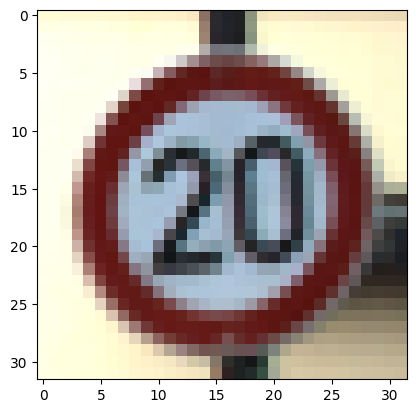

In [68]:
sign_path = imgs_path + "/0/00000_00004_00029.png"

img = Image.open(sign_path)
img = img.resize((32,32))
sr = np.array(img)
plt.imshow(img)
plt.show()

In [69]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(data,labels,test_size=0.2,random_state=42)

print("training shape: ", x_train.shape, y_train.shape)
print("testing shape: ", x_test.shape, y_test.shape)

from keras.utils import to_categorical
y_train = to_categorical(y_train, 43)
y_test = to_categorical(y_test, 43)

training shape:  (31367, 32, 32, 3) (31367,)
testing shape:  (7842, 32, 32, 3) (7842,)


In [70]:
x_train = x_train / 255.0
x_test = x_test / 255.0

In [71]:
from tensorflow.keras.models import Model

base_model = VGG16(weights='imagenet', include_top=False, input_shape=(32, 32, 3))

for layer in base_model.layers:
    layer.trainable = False
    

x = base_model.output
x = Flatten()(x)
x = Dense(512, activation='relu')(x)
x = Dropout(0.1)(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.1)(x)
x = Dense(64, activation='relu')(x)
x = Dropout(0.1)(x)
predictions = Dense(43, activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=predictions)

In [ ]:
model.compile(
    loss="categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

epochs = 5

history = model.fit(
    x_train,
    y_train,
    epochs=epochs,
    batch_size=64,
    validation_data=(x_test, y_test)
)

Epoch 1/5
 99/491 ━━━━━━━━━━━━━━━━━━━━ 51s 132ms/step - accuracy: 0.1623 - loss: 3.1708

In [ ]:
import matplotlib.pyplot as plt

plt.figure(0)
plt.plot(history.history['accuracy'], label="Training accuracy")
plt.plot(history.history['val_accuracy'], label="Validation accuracy")
plt.title("Model Accuracy Over Epochs")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

plt.figure(1)
plt.plot(history.history['loss'], label="Training loss")
plt.plot(history.history['val_loss'], label="Validation loss")
plt.title("Model Loss Over Epochs")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.show()

In [ ]:
from sklearn.metrics import accuracy_score
import pandas as pd
import numpy as np
from PIL import Image

test = pd.read_csv(os.path.join(path,"Test.csv"))

test_labels = test['ClassId'].values
test_imgs = test['Path'].values

test_img_path = os.path.join(path,"Test")

test_data = []
for img in test_imgs:
    im = Image.open(os.path.join(test_img_path, str(img))
    im = im.resize((30,30))
    im = np.array(im)
    test_data.append(im)

test_data = np.array(test_data)

predictions = model.predict(test_data)
predicted_classes = np.argmax(predictions)

print("Accuracy:", accuracy_score(test_labels, predicted_classes))

model.save('traffic_classifier.h5')